In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Food_Delivery_Times.csv')

df.shape
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [25]:
df.shape

(1000, 9)

In [26]:
df.columns.to_list()

['Order_ID',
 'Distance_km',
 'Weather',
 'Traffic_Level',
 'Time_of_Day',
 'Vehicle_Type',
 'Preparation_Time_min',
 'Courier_Experience_yrs',
 'Delivery_Time_min']

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [28]:
# checking missing values
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [31]:
# Fill missing categorical values with the most common value
categorical_columns = [
    "Weather",
    "Traffic_Level",
    "Time_of_Day"
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing courier experience with the median
df["Courier_Experience_yrs"] = df["Courier_Experience_yrs"].fillna(
    df["Courier_Experience_yrs"].median()
)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64


In [32]:
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Total missing values: 0
Total duplicate rows: 0
Dataset shape: (1000, 9)


In [33]:
print(df["Delivery_Time_min"].describe())

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64


In [34]:
# Calculate overall delivery performance
total_orders = len(df)

late_orders = (df["Delivery_Time_min"] > 60).sum()

on_time_orders = (df["Delivery_Time_min"] <= 60).sum()

late_percentage = (late_orders / total_orders) * 100

print("Total Orders:", total_orders)
print("Late Orders:", late_orders)
print("Orders Delivered Within 60 Minutes:", on_time_orders)
print(f"Late Delivery Percentage: {late_percentage:.2f}%")

Total Orders: 1000
Late Orders: 415
Orders Delivered Within 60 Minutes: 585
Late Delivery Percentage: 41.50%


In [35]:
traffic_analysis = (
    df.groupby("Traffic_Level")["Delivery_Time_min"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

traffic_analysis

,count,mean,median
Traffic_Level,,,
High,197,64.81,65.0
Medium,420,56.45,54.0
Low,383,52.89,51.0


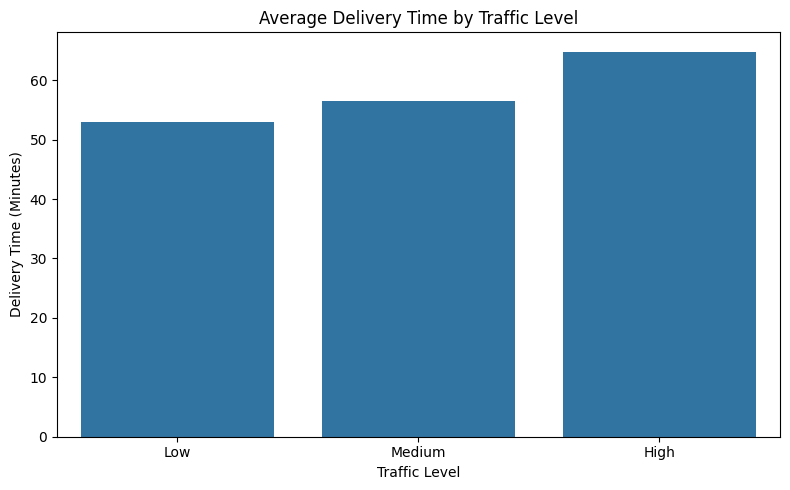

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Traffic_Level",
    y="Delivery_Time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

In [37]:
# Compare delivery time across distance groups

df["Distance_Group"] = pd.cut(
    df["Distance_km"],
    bins=[0, 3, 6, 10, float("inf")],
    labels=["0-3 km", "3-6 km", "6-10 km", "10+ km"],
    include_lowest=True
)

distance_analysis = (
    df.groupby("Distance_Group", observed=False)["Delivery_Time_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(distance_analysis)

                count   mean  median
Distance_Group                      
0-3 km            144  31.40    30.0
3-6 km            159  40.69    39.0
6-10 km           186  50.20    48.0
10+ km            511  71.24    70.0


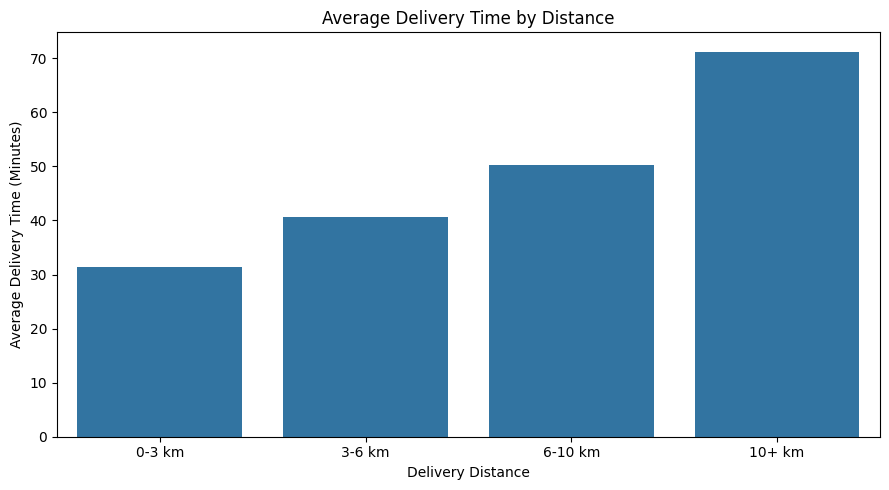

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Distance_Group",
    y="Delivery_Time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Distance")
plt.xlabel("Delivery Distance")
plt.ylabel("Average Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

In [39]:
# Group preparation time into ranges
df["Preparation_Group"] = pd.cut(
    df["Preparation_Time_min"],
    bins=[0, 10, 20, 30, float("inf")],
    labels=["0-10 min", "11-20 min", "21-30 min", "30+ min"],
    include_lowest=True
)

preparation_analysis = (
    df.groupby("Preparation_Group", observed=False)["Delivery_Time_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(preparation_analysis)

                   count   mean  median
Preparation_Group                      
0-10 min             246  47.31    47.0
11-20 min            391  55.76    55.0
21-30 min            363  64.16    62.0
30+ min                0    NaN     NaN


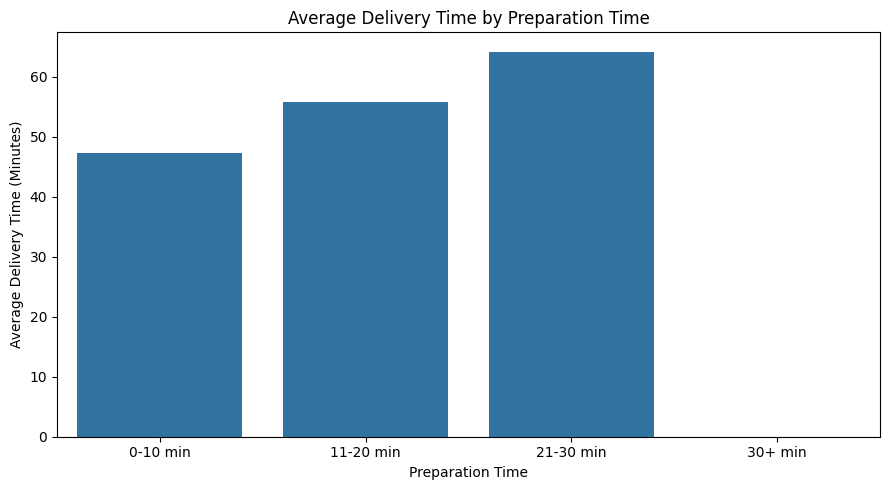

In [40]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Preparation_Group",
    y="Delivery_Time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Preparation Time")
plt.xlabel("Preparation Time")
plt.ylabel("Average Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

In [41]:
weather_analysis = (
    df.groupby("Weather")["Delivery_Time_min"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print(weather_analysis)

         count   mean  median
Weather                      
Snowy       97  67.11    66.0
Rainy      204  59.79    57.5
Foggy      103  59.47    59.0
Windy       96  55.46    55.0
Clear      500  53.15    52.0


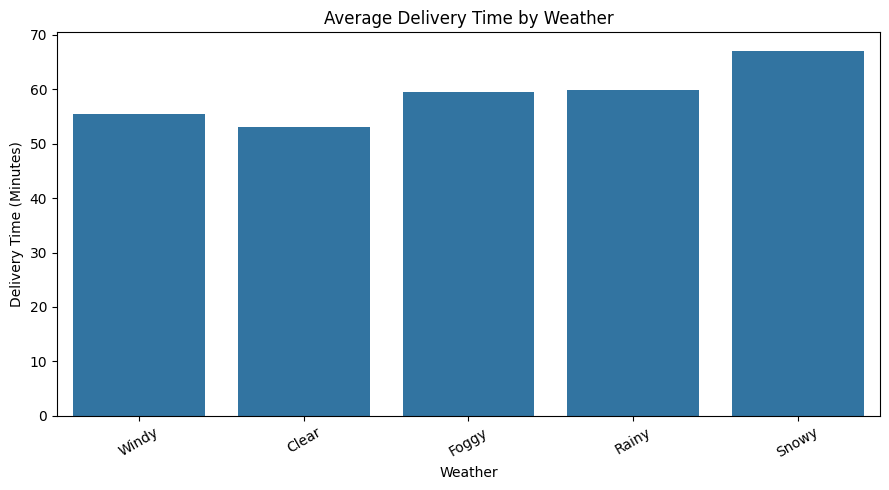

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Weather",
    y="Delivery_Time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Delivery Time (Minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [43]:
# Group couriers by years of experience
df["Experience_Group"] = pd.cut(
    df["Courier_Experience_yrs"],
    bins=[-0.01, 1, 3, 5, float("inf")],
    labels=["0-1 years", "1-3 years", "3-5 years", "5+ years"],
    include_lowest=True
)

experience_analysis = (
    df.groupby("Experience_Group", observed=False)["Delivery_Time_min"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print(experience_analysis)

                  count   mean  median
Experience_Group                      
0-1 years           198  60.37    60.0
1-3 years           179  57.01    55.0
3-5 years           214  56.63    54.5
5+ years            409  54.90    53.0


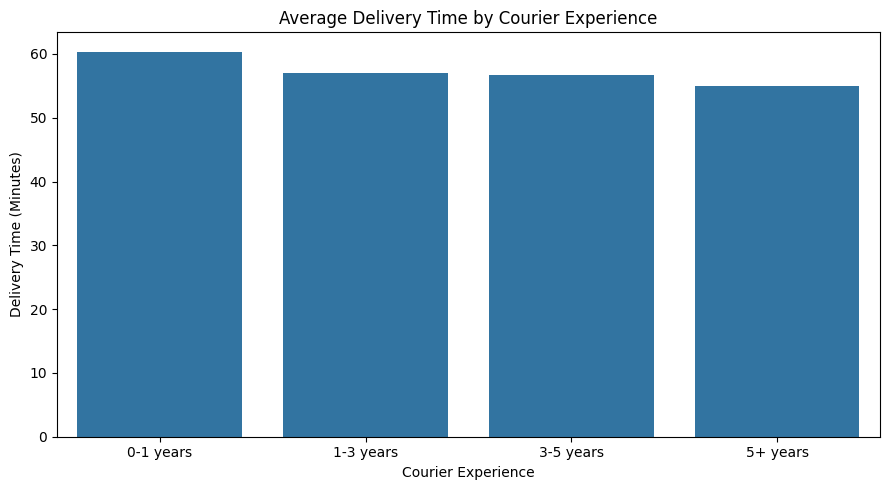

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Experience_Group",
    y="Delivery_Time_min",
    errorbar=None
)

plt.title("Average Delivery Time by Courier Experience")
plt.xlabel("Courier Experience")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

In [45]:
total_orders = len(df)

avg_delivery_time = df["Delivery_Time_min"].mean()

median_delivery_time = df["Delivery_Time_min"].median()

late_orders = (df["Delivery_Time_min"] > 60).sum()

late_delivery_rate = late_orders / total_orders * 100

avg_distance = df["Distance_km"].mean()

avg_preparation_time = df["Preparation_Time_min"].mean()

print("TOTAL ORDERS:", total_orders)
print(f"AVERAGE DELIVERY TIME: {avg_delivery_time:.2f} minutes")
print(f"MEDIAN DELIVERY TIME: {median_delivery_time:.2f} minutes")
print("LATE ORDERS:", late_orders)
print(f"LATE DELIVERY RATE: {late_delivery_rate:.2f}%")
print(f"AVERAGE DISTANCE: {avg_distance:.2f} km")
print(f"AVERAGE PREPARATION TIME: {avg_preparation_time:.2f} minutes")

TOTAL ORDERS: 1000
AVERAGE DELIVERY TIME: 56.73 minutes
MEDIAN DELIVERY TIME: 55.50 minutes
LATE ORDERS: 415
LATE DELIVERY RATE: 41.50%
AVERAGE DISTANCE: 10.06 km
AVERAGE PREPARATION TIME: 16.98 minutes


In [46]:
summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Average Delivery Time",
        "Median Delivery Time",
        "Late Orders",
        "Late Delivery Rate",
        "Average Distance",
        "Average Preparation Time"
    ],
    "Value": [
        total_orders,
        round(avg_delivery_time, 2),
        round(median_delivery_time, 2),
        late_orders,
        round(late_delivery_rate, 2),
        round(avg_distance, 2),
        round(avg_preparation_time, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Orders,1000.00
1,Average Delivery Time,56.73
2,Median Delivery Time,55.50
3,Late Orders,415.00
4,Late Delivery Rate,41.50
5,Average Distance,10.06
6,Average Preparation Time,16.98


In [47]:
# Export the cleaned dataset
df.to_csv("food_delivery_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
